# Used Car Price Estimator: Data Exploration

In this notebook I take a first look at the Craigslist used cars dataset from Kaggle. My goal is to understand what is in the data and what needs cleaning before I train a model to predict the listing price of a used car.

Source: https://www.kaggle.com/datasets/austinreese/craigslist-carstrucks-data (CC0 license, last updated on Kaggle in May 2021)

In [227]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Loading the data

The raw file is about 1.4 GB, mostly because of the long seller descriptions. I only load the columns that could be useful as features or as the target, which keeps memory use down.

In [228]:
DATA_PATH = "../data/raw/vehicles.csv"

use_cols = [
    "price", "year", "manufacturer", "model", "condition", "cylinders",
    "fuel", "odometer", "title_status", "transmission", "drive",
    "type", "paint_color", "state", "posting_date",
]

df = pd.read_csv(DATA_PATH, usecols=use_cols)
df.shape

(426880, 15)

In [229]:
df.head()

,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,drive,type,paint_color,state,posting_date
0,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,az,NaN
1,11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ar,NaN
2,21000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fl,NaN
3,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ma,NaN
4,4900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nc,NaN


In [230]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   price         426880 non-null  int64  
 1   year          425675 non-null  float64
 2   manufacturer  409234 non-null  str    
 3   model         421603 non-null  str    
 4   condition     252776 non-null  str    
 5   cylinders     249202 non-null  str    
 6   fuel          423867 non-null  str    
 7   odometer      422480 non-null  float64
 8   title_status  418638 non-null  str    
 9   transmission  424324 non-null  str    
 10  drive         296313 non-null  str    
 11  type          334022 non-null  str    
 12  paint_color   296677 non-null  str    
 13  state         426880 non-null  str    
 14  posting_date  426812 non-null  str    
dtypes: float64(2), int64(1), str(12)
memory usage: 48.9 MB


## 2. Missing values

Next I check how much of each column is missing. This matters because my app will run into the same gaps when a user leaves details out of their question.

In [231]:
missing = (
    df.isna()
    .mean()
    .mul(100)
    .round(1)
    .sort_values(ascending=False)
    .rename("percent_missing")
    .to_frame()
)
missing

,percent_missing
cylinders,41.60
condition,40.80
drive,30.60
paint_color,30.50
type,21.80
manufacturer,4.10
title_status,1.90
model,1.20
odometer,1.00
fuel,0.70


Condition and cylinders are each missing in about 41 percent of listings. Drive and paint color are missing in about 31 percent, and vehicle type in about 22 percent. Every other column is missing in less than 5 percent of listings. Because condition is missing so often, I will treat it as optional in the app instead of requiring it, and I will handle the gaps in preprocessing without throwing away nearly half the data.

## 3. The price column

Price is what my model will predict, so I need to know if it can be trusted. Listings on Craigslist often have placeholder prices like 0 or 1, and some sellers type in absurdly large numbers. I look at the spread of prices and count the suspicious ones before I decide how to clean them.

In [232]:
df["price"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])

count         426,880.00
mean           75,199.03
std        12,182,282.17
min                 0.00
1%                  0.00
5%                  0.00
25%             5,900.00
50%            13,950.00
75%            26,485.75
95%            44,500.00
99%            66,995.00
max     3,736,928,711.00
Name: price, dtype: float64

In [233]:
print("Price equal to 0:", (df["price"] == 0).sum())
print("Price under 500:", (df["price"] < 500).sum())
print("Price over 100,000:", (df["price"] > 100_000).sum())
print("Price over 1,000,000:", (df["price"] > 1_000_000).sum())

Price equal to 0: 32895
Price under 500: 42094
Price over 100,000: 655
Price over 1,000,000: 53


The price column has serious problems. The median price is 13,950 dollars, but the mean is about 75,000 dollars and the maximum is over 3.7 billion dollars, so a handful of absurd listings pull the average far up. At the other end, 32,895 listings (about 8 percent) have a price of 0, and 42,094 listings are priced under 500 dollars. These are most likely placeholder prices, such as listings that say call for price. I also found 655 listings over 100,000 dollars and 53 over one million dollars, which are likely typos or exotic cars that my app is not meant to price.

I decided to keep listings priced between 500 and 100,000 dollars. This removes about 10 percent of the rows and keeps the everyday used cars my app is built for. I will make both cutoffs settings in the config file so I can change them later and see how the results change.

In [234]:
MIN_PRICE = 500
MAX_PRICE = 100_000

df_clean = df[df["price"].between(MIN_PRICE, MAX_PRICE)].copy()

print("Rows kept:", len(df_clean), "of", len(df))
print("Percent removed:", round(100 * (1 - len(df_clean) / len(df)), 1))
df_clean["price"].describe()

Rows kept: 384131 of 426880
Percent removed: 10.0


count   384,131.00
mean     19,161.45
std      14,412.29
min         500.00
25%       7,800.00
50%      15,900.00
75%      27,990.00
max     100,000.00
Name: price, dtype: float64

## 4. What the cleaned prices look like

Now that the obvious junk is gone, I plot the distribution of prices to see its shape. This helps me decide later if I should predict the price directly or work with a transformed version of it.

In [235]:
from matplotlib.ticker import FuncFormatter

BLUE = "#2a78d6"
INK = "#0b0b0b"
MUTED = "#898781"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS,
    "axes.labelcolor": MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "text.color": INK,
    "font.size": 11,
})

thousands = FuncFormatter(lambda x, _: f"{x:,.0f}")

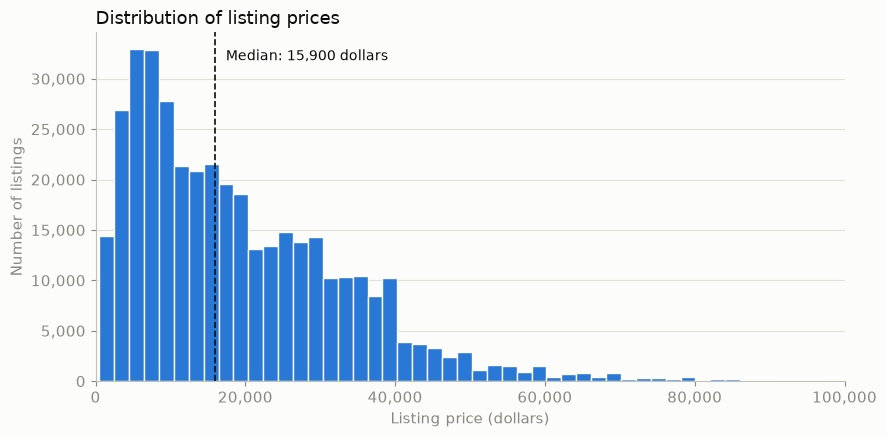

In [236]:
fig, ax = plt.subplots(figsize=(9, 4.5))

ax.hist(df_clean["price"], bins=50, color=BLUE, edgecolor=SURFACE, linewidth=1)

median_price = df_clean["price"].median()
ax.axvline(median_price, color=INK, linewidth=1.2, linestyle="--")
ax.text(
    median_price + 1500,
    ax.get_ylim()[1] * 0.92,
    f"Median: {median_price:,.0f} dollars",
    color=INK,
    fontsize=10,
)

ax.set_title("Distribution of listing prices", loc="left", fontsize=13)
ax.set_xlabel("Listing price (dollars)")
ax.set_ylabel("Number of listings")
ax.set_xlim(0, MAX_PRICE)
ax.xaxis.set_major_formatter(thousands)
ax.yaxis.set_major_formatter(thousands)

plt.tight_layout()
plt.show()

The distribution is skewed to the right. Most listings are priced under 30,000 dollars, with the biggest group between about 5,000 and 10,000 dollars, and then the counts taper off slowly toward 100,000 dollars. The median is 15,900 dollars. Because of this long tail, a model trained on the raw price may care too much about getting the expensive cars right and not enough about the cheap ones. I will try predicting the log of the price as one of my experiments and compare it with predicting the raw price.

## 5. Checking year and odometer

Price had a lot of junk in it, so I expect year and odometer to have some too. I will start with year. A car can't be from the future, and very old years are probably typos or classics that don't fit an everyday car estimator.

In [237]:
print(df_clean.shape)
print("missing year:", df_clean["year"].isna().sum())
print(df_clean["year"].describe())

(384131, 15)
missing year: 1172
count   382,959.00
mean      2,010.97
std           9.59
min       1,900.00
25%       2,008.00
50%       2,013.00
75%       2,017.00
max       2,022.00
Name: year, dtype: float64


In [238]:
years = df_clean["year"].dropna().sort_values()
print("oldest:", years.head(15).tolist())
print("newest:", years.tail(15).tolist())

oldest: [1900.0, 1900.0, 1900.0, 1900.0, 1901.0, 1901.0, 1905.0, 1909.0, 1910.0, 1910.0, 1913.0, 1913.0, 1915.0, 1916.0, 1916.0]
newest: [2022.0, 2022.0, 2022.0, 2022.0, 2022.0, 2022.0, 2022.0, 2022.0, 2022.0, 2022.0, 2022.0, 2022.0, 2022.0, 2022.0, 2022.0]


In [239]:
for cutoff in [1960, 1980, 1990, 2000]:
    print("older than", cutoff, ":", (df_clean["year"] < cutoff).sum())

print("after 2022:", (df_clean["year"] > 2022).sum())

older than 1960 : 2283
older than 1980 : 7954
older than 1990 : 11787
older than 2000 : 24166
after 2022: 0


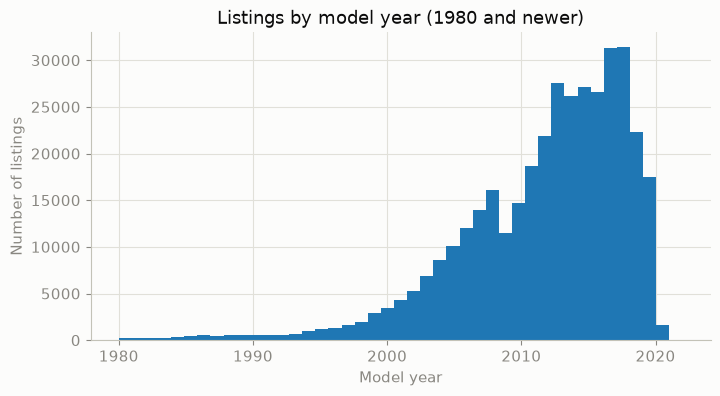

In [240]:
df_clean.loc[df_clean["year"] >= 1980, "year"].plot(kind="hist", bins=43, figsize=(8, 4))
plt.title("Listings by model year (1980 and newer)")
plt.xlabel("Model year")
plt.ylabel("Number of listings")
plt.show()

**Year findings.** Year has 1,172 missing values, and some listings claim to be from as far back as 1900, which is not a real everyday car. Nothing is newer than 2022. Since this app is for everyday used cars, I will keep model years from 1990 on and drop rows with no year. That removes about 3 percent of the rows. Older cars are classics and collectibles, and their prices work differently. The data was collected in 2021, so there are very few of the newest cars, and I will note that as a limitation in the README.

**Odometer.** Next I check odometer for the same kinds of junk: missing values, zeros, and impossibly high numbers.

In [241]:
print("missing odometer:", df_clean["odometer"].isna().sum())
print(df_clean["odometer"].describe())
print(df_clean["odometer"].quantile([0.01, 0.05, 0.5, 0.95, 0.99, 0.999]))

missing odometer: 2115
count      382,016.00
mean        98,598.66
std        192,028.64
min              0.00
25%         38,379.00
50%         87,814.50
75%        136,000.00
max     10,000,000.00
Name: odometer, dtype: float64
0.01          22.00
0.05       7,080.00
0.50      87,814.50
0.95     206,000.00
0.99     280,000.00
1.00   1,111,111.00
Name: odometer, dtype: float64


In [242]:
print("exactly zero:", (df_clean["odometer"] == 0).sum())
print("under 100:", (df_clean["odometer"] < 100).sum())

for cutoff in [300000, 500000, 1000000]:
    print("over", cutoff, ":", (df_clean["odometer"] > cutoff).sum())

exactly zero: 1066
under 100: 4526
over 300000 : 2704
over 500000 : 1145
over 1000000 : 419


In [243]:
low = df_clean[df_clean["odometer"] < 100]
print("rows under 100 miles:", len(low))
print("older than 2018:", (low["year"] < 2018).sum())
print(low["year"].value_counts().sort_index().tail(10))

rows under 100 miles: 4526
older than 2018: 2948
year
2,013.00    162
2,014.00    151
2,015.00    233
2,016.00    107
2,017.00    126
2,018.00    106
2,019.00    149
2,020.00    523
2,021.00    660
2,022.00     20
Name: count, dtype: int64


**Odometer findings.** Odometer has 2,115 missing values and some impossible readings. The highest value is 10,000,000, and 419 listings are over 1,000,000, with repeated digits like 1,111,111 that look like typos. Almost every real car is under 300,000 miles, so I will cap odometer at 300,000, which removes less than 1 percent of the rows. At the low end, 4,526 listings show under 100 miles, and 2,948 of them are cars from before 2018, so those are placeholders and not real readings. The count jumps for 2020 and 2021 cars, which looks like real brand new cars. I will drop readings under 100 miles only for cars older than 2020 and keep them for newer cars. I will also drop rows with no odometer, the same as year.

In [244]:
df_check = df_clean.dropna(subset=["year", "odometer"])
df_check = df_check[df_check["year"] >= 1990]
df_check = df_check[df_check["odometer"] <= 300000]
placeholder = (df_check["odometer"] < 100) & (df_check["year"] < 2020)
df_check = df_check[~placeholder]

print(len(df_check), "rows left")
print(round(len(df_check) / len(df_clean) * 100, 1), "percent of the price-cleaned rows")

364252 rows left
94.8 percent of the price-cleaned rows


**What is left.** After applying the year and odometer rules together, I have 364,252 rows, which is about 94.8 percent of the price-cleaned rows. That is plenty to train on. This cell is only a count. The real filtering will go in preprocess.py, and the cutoffs will live in config.yaml.

## 6. Categorical columns

The numeric columns are checked, so now I look at the text columns. The one I am most worried about is model, because people type it in by hand. I start by counting how many different values each text column has.

In [245]:
cat_cols = ["manufacturer", "model", "condition", "cylinders", "fuel",
            "title_status", "transmission", "drive", "type", "paint_color", "state"]

for col in cat_cols:
    print(col, ":", df_check[col].nunique(), "unique values,", round(df_check[col].isna().mean() * 100, 1), "percent missing")

manufacturer : 41 unique values, 3.1 percent missing
model : 23929 unique values, 0.9 percent missing
condition : 6 unique values, 37.9 percent missing
cylinders : 8 unique values, 41.1 percent missing
fuel : 5 unique values, 0.6 percent missing
title_status : 6 unique values, 1.7 percent missing
transmission : 3 unique values, 0.4 percent missing
drive : 3 unique values, 30.1 percent missing
type : 13 unique values, 20.7 percent missing
paint_color : 12 unique values, 28.5 percent missing
state : 51 unique values, 0.0 percent missing


In [246]:
for col in ["manufacturer", "fuel", "title_status", "transmission", "drive", "type"]:
    print(df_check[col].value_counts(dropna=False).head(12))
    print()

manufacturer
ford             60279
chevrolet        45333
toyota           30140
honda            19070
nissan           16648
jeep             16157
ram              15747
gmc              14581
bmw              13132
NaN              11115
dodge            11054
mercedes-benz     9420
Name: count, dtype: int64

fuel
gas         304947
other        27020
diesel       23943
hybrid        4716
NaN           2067
electric      1559
Name: count, dtype: int64

title_status
clean         345803
rebuilt         6825
NaN             6310
salvage         3607
lien            1364
missing          243
parts only       100
Name: count, dtype: int64

transmission
automatic    284816
other         60211
manual        17781
NaN            1444
Name: count, dtype: int64

drive
4wd    113781
NaN    109602
fwd     93409
rwd     47460
Name: count, dtype: int64

type
sedan          75704
NaN            75534
SUV            66938
pickup         39261
truck          28359
other          19041
coupe      

In [247]:
for col in ["title_status", "transmission", "drive"]:
    print(df_check[col].value_counts(dropna=False))
    print()

title_status
clean         345803
rebuilt         6825
NaN             6310
salvage         3607
lien            1364
missing          243
parts only       100
Name: count, dtype: int64

transmission
automatic    284816
other         60211
manual        17781
NaN            1444
Name: count, dtype: int64

drive
4wd    113781
NaN    109602
fwd     93409
rwd     47460
Name: count, dtype: int64



In [248]:
model_counts = df_check["model"].value_counts()
print(model_counts.head(25))
print()

for n in [50, 100, 200, 500, 1000]:
    share = model_counts.head(n).sum() / model_counts.sum() * 100
    print("top", n, "models cover", round(share, 1), "percent of rows")

print()
print("models that appear only once:", (model_counts == 1).sum())
print(model_counts[model_counts == 1].sample(15, random_state=42).index.tolist())

model
f-150             6756
silverado 1500    4273
1500              3638
camry             2694
accord            2592
silverado         2557
civic             2472
escape            2428
wrangler          2377
altima            2348
2500              2334
tacoma            2284
explorer          2155
grand cherokee    2130
corolla           1909
equinox           1687
mustang           1673
cr-v              1660
focus             1587
fusion            1571
rav4              1472
malibu            1460
tahoe             1444
grand caravan     1429
sonata            1410
Name: count, dtype: int64

top 50 models cover 24.3 percent of rows
top 100 models cover 33.9 percent of rows
top 200 models cover 44.5 percent of rows
top 500 models cover 59.1 percent of rows
top 1000 models cover 70.3 percent of rows

models that appear only once: 11810
['super duty e-250', 'f150 king ranch super crew', '528i 5 series', 'beetle-classic 2.5l pzev 52k miles leather', '2008 Doge SXT 1/2 ton 4x4', 'm

In [249]:
mm = df_check["manufacturer"].fillna("unknown") + " " + df_check["model"].fillna("unknown")
print("unique manufacturer + model:", mm.nunique())

mm_counts = mm.value_counts()
for min_n in [10, 25, 50, 100, 200]:
    kept = mm_counts[mm_counts >= min_n]
    print("at least", min_n, "listings:", len(kept), "models, covering",
          round(kept.sum() / mm_counts.sum() * 100, 1), "percent of rows")

unique manufacturer + model: 24310
at least 10 listings: 3917 models, covering 88.0 percent of rows
at least 25 listings: 1996 models, covering 80.0 percent of rows
at least 50 listings: 1120 models, covering 71.7 percent of rows
at least 100 listings: 600 models, covering 61.7 percent of rows
at least 200 listings: 287 models, covering 49.9 percent of rows


In [250]:
print(df_check.groupby("title_status")["price"].agg(["count", "median"]).sort_values("median", ascending=False))

               count    median
title_status                  
lien            1364 18,000.00
clean         345803 16,291.00
rebuilt         6825 10,450.00
salvage         3607  7,500.00
missing          243  2,000.00
parts only       100  1,575.00


**Categorical findings so far.** Manufacturer is clean, with 41 lowercase values and no duplicates near the top. Fuel and transmission both have a large "other" group, about 7 percent and 16 percent of rows, and I will keep those as their own category since I can't tell what is inside them. Drive is missing for about 30 percent of rows, so it will be an optional input. Title status has clean, rebuilt, salvage, lien, missing, and parts only. I will drop the 100 parts only rows because the app is for everyday cars. Rebuilt and salvage are small groups, about 2 percent and 1 percent of rows, but there are enough of them for a model to learn a price difference.

**Model column.** Model is free text with 23,929 unique values, and some of them are just numbers like 1500 that could belong to several brands. About half of the model values appear only once, but those are only about 3 percent of the rows, and most of them are real cars with extra words or typos. I combine manufacturer and model into one feature, which gives 24,310 unique values. Only about 2,000 of those have at least 25 listings, and they cover 80 percent of the rows. Instead of writing cleaning rules by hand, I will let the encoder group everything rarer into one infrequent category. I may try a few thresholds as one of my MLflow experiments.

**Title status and price.** The median price for a clean title is 16,291 dollars, for rebuilt it is 10,450 dollars, and for salvage it is 7,500 dollars. A rebuilt title takes about a third off the price and salvage takes about half, which is the pattern I want the model to learn. I will drop the parts only rows and the rows where the title status is literally the word missing, because their median prices are only about 1,575 and 2,000 dollars, which looks like junk and not everyday cars.

In [251]:
for col in ["condition", "cylinders", "type", "paint_color"]:
    print(df_check[col].value_counts(dropna=False))
    print()

print(df_check.groupby("condition")["price"].median().sort_values())

condition
NaN          137925
good         113713
excellent     87233
like new      18803
fair           5203
new             921
salvage         454
Name: count, dtype: int64

cylinders
NaN             149526
6 cylinders      83655
4 cylinders      67980
8 cylinders      58862
5 cylinders       1569
10 cylinders      1084
other              869
3 cylinders        567
12 cylinders       140
Name: count, dtype: int64

type
sedan          75704
NaN            75534
SUV            66938
pickup         39261
truck          28359
other          19041
coupe          15635
hatchback      15397
wagon           9495
van             7473
convertible     6142
mini-van        4418
offroad          449
bus              406
Name: count, dtype: int64

paint_color
NaN       103806
white      69159
black      55889
silver     38596
blue       27416
red        26512
grey       21600
green       6167
custom      5720
brown       5686
yellow      1573
orange      1564
purple       564
Name: count, dtype: 

In [252]:
print(df_check["type"].value_counts(dropna=False))

type
sedan          75704
NaN            75534
SUV            66938
pickup         39261
truck          28359
other          19041
coupe          15635
hatchback      15397
wagon           9495
van             7473
convertible     6142
mini-van        4418
offroad          449
bus              406
Name: count, dtype: int64


In [253]:
print(df_check["paint_color"].value_counts(dropna=False))

paint_color
NaN       103806
white      69159
black      55889
silver     38596
blue       27416
red        26512
grey       21600
green       6167
custom      5720
brown       5686
yellow      1573
orange      1564
purple       564
Name: count, dtype: int64


In [254]:
print(df_check.groupby("condition")["price"].agg(["count", "median"]).sort_values("median"))

            count    median
condition                  
salvage       454  2,000.00
fair         5203  2,500.00
excellent   87233 11,990.00
like new    18803 14,900.00
good       113713 21,590.00
new           921 21,800.00


**Condition, type, and paint color.** Condition is missing for about 38 percent of rows, and it behaves strangely. The median price for good is 21,590 dollars, but for excellent it is only 11,990 dollars and for like new it is 14,900 dollars. If it were a clean scale, the better conditions would cost more. My guess is that sellers use these labels very differently from each other. Because of that, I will treat condition as an unordered category and test the model with and without it. Type has 13 values and is missing for about 21 percent of rows. Pickup and truck are separate labels that overlap, so I will merge them into one group. Paint color is missing for about 28 percent of rows and I don't expect it to move the price much, so I will leave it out.

**Features I plan to use.** Year, manufacturer, model, and odometer will be required, since the price depends on them the most and the app can ask for them. Title status, fuel, transmission, drive, and type will be optional. When one of them is missing, it becomes its own unknown category and the row stays. Condition is optional too, but I will run an experiment with and without it and drop it if it does not help. I am leaving out cylinders because the engine is mostly implied by the model and year, and I am leaving out paint color because it is missing a lot and should not matter much. State is left out for now, and I may test it later.